In [1]:
import os
import pandas as pd
import yaml
import numpy as np
import matplotlib.pyplot as plt
from utils.eval_utils import load_trial_results, generate_summary_table, get_kfold_mean_metrics, plot_learning_curves
import torch
import random
from pytorch_lightning import seed_everything
from dataset.tracking_dataset import load_data_list
from sklearn.model_selection import train_test_split
from train.train_lstm import train_lstm_pipeline

#### Descargar logs

In [3]:
# !lightning download folder logs/bayesian_log/trial_8 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_8
# !lightning download folder logs/bayesian_log/trial_9 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_9
# !lightning download folder logs/bayesian_log/trial_10 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_10
# !lightning download folder logs/bayesian_log/trial_11 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_11
# !lightning download folder logs/bayesian_log/trial_12 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_12
# !lightning download folder logs/bayesian_log/trial_13 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_13
# !lightning download folder logs/bayesian_log/trial_14 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_14
# !lightning download folder logs/bayesian_log/trial_15 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_15
# !lightning download folder logs/bayesian_log/trial_16 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_16

## Optimización de Hiperparámetros

### Resultados de Bayesian Search loss - std

In [2]:
log_directory = '../../logs/bayesian_log'

trials = 20
folds = 5

df_results = load_trial_results(
    base_log_dir=log_directory,
    n_trials=trials,
    n_folds=folds
)

summary_table = generate_summary_table(df_results)
print("Tabla de Resumen Estadístico por Trial:")
display(summary_table)

/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.007203406243608278 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.0031806158701979223 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.17907345777926564 and num_layers=1
  warnings.warn("dropout 

Mejor combinación de hiperparámetros (Trial 15.0) basada en val_loss mínimo.
Tabla de Resumen Estadístico por Trial:


,Trial,Hidden Size,Num Layers,Dropout,Lr,Weight Decay,Trainable Params,MSE (Val),MAE (Val),RelAcc (Val),Folds,Mejor Trial
0,15.0,128,3,0.06,4.4e-04,3.5e-05,"344,193.0",10.869 ± 2.027,1.528 ± 0.181,0.980 ± 0.002,5.0,<-- MEJOR
1,18.0,128,2,0.05,7.6e-04,4.6e-05,"212,097.0",10.990 ± 1.492,1.505 ± 0.194,0.980 ± 0.003,5.0,
2,14.0,128,3,0.09,5.3e-04,3.6e-05,"344,193.0",11.475 ± 1.243,1.532 ± 0.112,0.980 ± 0.002,5.0,
3,13.0,64,3,0.08,5.1e-04,3.5e-05,"90,177.0",11.552 ± 1.385,1.606 ± 0.085,0.979 ± 0.001,5.0,
4,19.0,128,2,0.05,2.0e-03,1.3e-05,"212,097.0",11.668 ± 1.129,1.820 ± 0.197,0.977 ± 0.002,5.0,
5,17.0,128,3,0.12,3.5e-04,2.0e-05,"344,193.0",11.939 ± 1.597,1.579 ± 0.122,0.980 ± 0.002,5.0,
6,12.0,64,3,0.10,5.5e-04,4.3e-05,"90,177.0",12.502 ± 1.215,1.651 ± 0.084,0.979 ± 0.001,5.0,
7,1.0,64,1,0.01,1.6e-04,4.0e-06,"23,617.0",12.622 ± 1.116,1.883 ± 0.060,0.976 ± 0.001,5.0,
8,3.0,64,3,0.21,1.3e-03,7.4e-05,"90,177.0",12.767 ± 1.836,1.980 ± 0.269,0.975 ± 0.003,5.0,
9,16.0,128,3,0.04,2.7e-03,3.7e-05,"344,193.0",13.097 ± 0.975,1.911 ± 0.066,0.975 ± 0.001,5.0,


In [3]:
def plot_learning_curves(epoch_summary, title='Curva de Aprendizaje', save_path=None):
    plt.figure(figsize=(8, 5))
    plot_legend = False

    if 'mean_train_loss' in epoch_summary.columns and epoch_summary['mean_train_loss'].notna().any():
        plt.plot(epoch_summary['epoch'], epoch_summary['mean_train_loss'], label='Train Loss (promedio)')
        plt.fill_between(epoch_summary['epoch'],
                            epoch_summary['mean_train_loss'] - epoch_summary['std_train_loss'],
                            epoch_summary['mean_train_loss'] + epoch_summary['std_train_loss'],
                            alpha=0.2, label='Train Loss (±σ)')
        plot_legend = True

    if 'mean_val_loss' in epoch_summary.columns and epoch_summary['mean_val_loss'].notna().any():
        plt.plot(epoch_summary['epoch'], epoch_summary['mean_val_loss'], label='Validation Loss (promedio)')
        plt.fill_between(epoch_summary['epoch'],
                            epoch_summary['mean_val_loss'] - epoch_summary['std_val_loss'],
                            epoch_summary['mean_val_loss'] + epoch_summary['std_val_loss'],
                            alpha=0.2, label='Validation Loss (±σ)')
        plot_legend = True

    plt.title(title)
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.yscale('log')
    if plot_legend:
        plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight')
        print(f"Gráfica guardada en: {save_path}")

    plt.show()

In [4]:
best_params = df_results.iloc[0].to_dict()

Gráfica guardada en: ims/learning_curve_best_model.svg


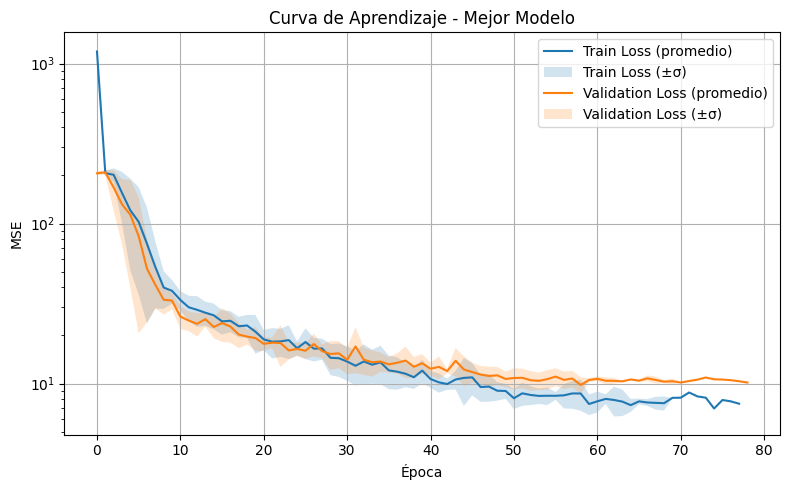

In [5]:
# Graficar curvas de aprendizaje
mean_metrics = get_kfold_mean_metrics(log_directory, best_params, folds)
plot_learning_curves(mean_metrics, 
                    title='Curva de Aprendizaje - Mejor Modelo',
                    save_path='ims/learning_curve_best_model.svg')


### Reentrenar modelo con mejores hiperparámetros

In [6]:
ALL_VIDEOS = [
    ('session1', 'center'),
    ('session1', 'left'),
    ('session1', 'right'),
    ('session2', 'center'),
    ('session2', 'left'),
    ('session2', 'right'),
    ('session3', 'center'),
    ('session3', 'left'),
    ('session3', 'right'),
    ('session4', 'center'),
    ('session4', 'left'),
    ('session4', 'right'),
    ('session5', 'center'),
    ('session5', 'left'),
    ('session5', 'right'),
    ('session6', 'center'),
    ('session6', 'left'),
    ('session6', 'right'),
]

In [7]:
seed = 47
seed_everything(seed)
random.seed(seed)
np.random.seed(seed)

full_list = load_data_list(ALL_VIDEOS, results_folder='../../results_instance', feature_path='all_features')
all_idx = np.arange(len(full_list))
train_val_idx, test_idx = train_test_split(
    all_idx, test_size=0.2, random_state=seed, shuffle=True
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.2, random_state=seed, shuffle=True
)
train_list = [full_list[i] for i in train_idx]
val_list = [full_list[i] for i in val_idx]
test_list = [full_list[i] for i in test_idx]

Seed set to 47


In [13]:
from dataset.tracking_datamodule import TrackingDataModule
from models.lstm_model import TrackingLSTM
from pytorch_lightning import Trainer
import pytorch_lightning as pl

In [15]:
data_module = TrackingDataModule(
    data_list=full_list,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    batch_size=4,
    split_ratio=(0.64, 0.16, 0.2),
    num_workers=4
)

In [21]:
best_model_path = 'logs/best_model/version_0/'
ckpt_path = 'checkpoints/epoch=35-step=106992.ckpt'
model = TrackingLSTM.load_from_checkpoint(best_model_path + ckpt_path)
model.eval()

TrackingLSTM(
  (lstm): LSTM(26, 128, num_layers=3, batch_first=True, dropout=0.06465945488805763)
  (dropout): Dropout(p=0.06465945488805763, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (loss_fn): MSELoss()
  (train_mse): MeanSquaredError()
  (train_mae): MeanAbsoluteError()
  (train_acc): RelativeRegressionAccuracy()
  (val_mse): MeanSquaredError()
  (val_mae): MeanAbsoluteError()
  (val_acc): RelativeRegressionAccuracy()
  (test_mse): MeanSquaredError()
  (test_mae): MeanAbsoluteError()
  (test_acc): RelativeRegressionAccuracy()
)

In [17]:
hparams = {
        'hidden_size': 128,
        'num_layers': 3,
        'dropout': 0.06465945488805763,
        'lr': 0.0004388375502916408,
        'weight_decay': 3.549240290879743e-05,
    }
trainer = Trainer(
        max_epochs=100,
        accelerator="auto",
        devices="auto",
        deterministic=False,
    )
trainer.test(model, datamodule=data_module)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA L40S') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


Preparing data for TrackingDataModule...
Setting up TrackingDataModule with 18577 samples.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9787623882293701     │
│         test_loss         │    12.256915092468262     │
│         test_mae          │    1.6608253717422485     │
│         test_mse          │    12.256915092468262     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 12.256915092468262,
  'test_mse': 12.256915092468262,
  'test_mae': 1.6608253717422485,
  'test_acc': 0.9787623882293701}]

In [18]:
predictions = trainer.predict(model, dataloaders=data_module.test_dataloader())
pred_df = pd.DataFrame(predictions, columns=["pred", "target"])

Preparing data for TrackingDataModule...
Setting up TrackingDataModule with 18577 samples.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [19]:
df_pred = pd.DataFrame(
    [
        (
            pred[i].item(),
            real[i].item(),
            abs(pred[i].item() - real[i].item())
        )
        for (pred, real) in predictions
        for i in range(len(pred))
    ],
    columns=["Velocidad Predicha", "Velocidad Real", "Error km/h"]
)
df_pred.head(20)

,Velocidad Predicha,Velocidad Real,Error km/h
0,76.641968,76.532402,0.109566
1,63.476536,63.741600,0.265064
2,124.341003,126.986397,2.645393
3,76.529373,76.608002,0.078629
4,77.742844,78.533997,0.791153
5,88.245331,86.666397,1.578934
6,77.261154,76.255203,1.005951
7,72.092155,72.615601,0.523445
8,74.088188,75.171600,1.083412
9,67.029808,67.078796,0.048988


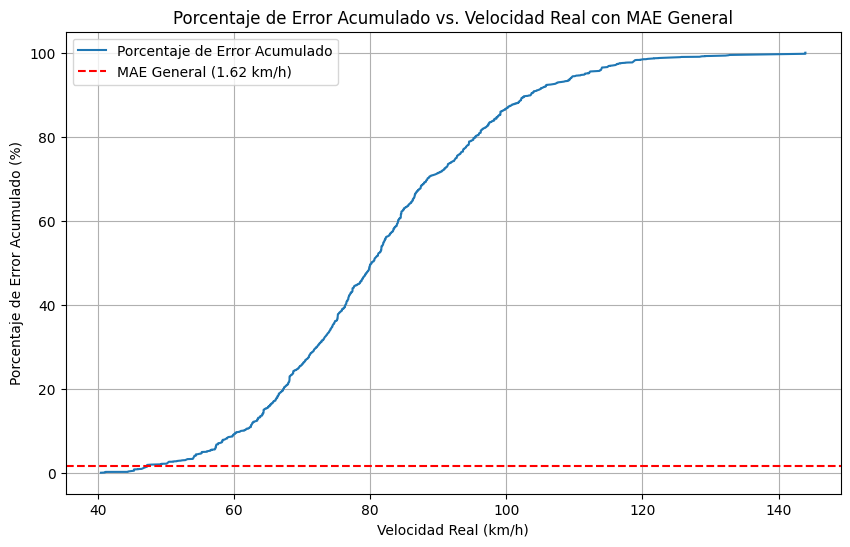

In [16]:
# 1. Gráfica de error acumulado porcentual vs. Velocidad Real con Error Absoluto Medio
df_sorted_speed = df_pred.sort_values('Velocidad Real').reset_index(drop=True)
df_sorted_speed['Error Absoluto'] = abs(df_sorted_speed['Error km/h'])

# Calcular el error acumulado y el porcentaje acumulado
df_sorted_speed['Error Acumulado'] = df_sorted_speed['Error Absoluto'].cumsum()
df_sorted_speed['Porcentaje Error Acumulado'] = (df_sorted_speed['Error Acumulado'] / df_sorted_speed['Error Absoluto'].sum()) * 100

# Calcular el Error Absoluto Medio (MAE) general
mae_general = df_sorted_speed['Error Absoluto'].mean()

plt.figure(figsize=(10, 6))
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Porcentaje Error Acumulado'], label='Porcentaje de Error Acumulado')

# Agregar línea horizontal para el MAE general
plt.axhline(y=mae_general, color='red', linestyle='--', label=f'MAE General ({mae_general:.2f} km/h)')

plt.title('Porcentaje de Error Acumulado vs. Velocidad Real con MAE General')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Porcentaje de Error Acumulado (%)')
plt.legend()
plt.grid(True)
plt.show()


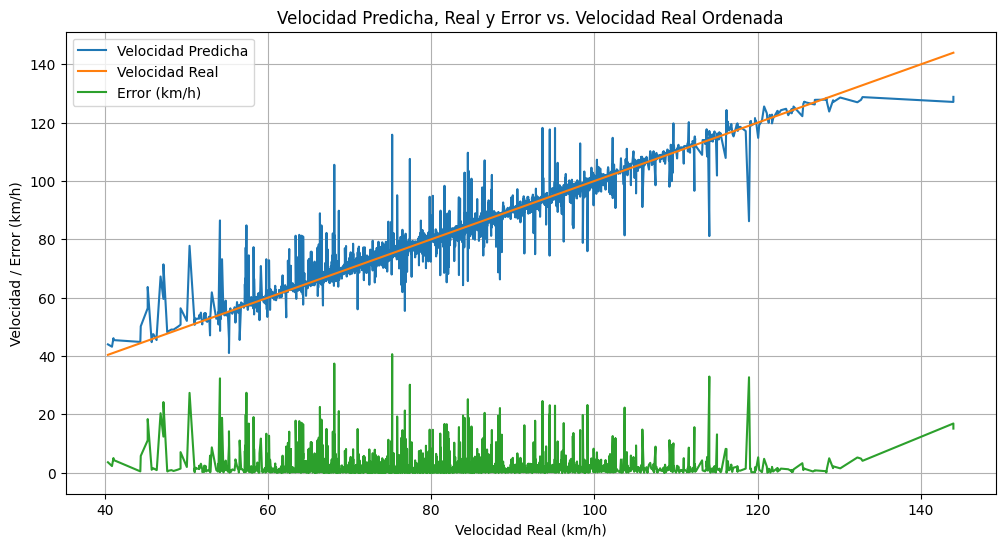

In [18]:
# 2. Gráfica de triple línea (Predicha, Real, Error) vs. Velocidad Real ordenada
df_sorted_speed = df_pred.sort_values('Velocidad Real').reset_index(drop=True)

plt.figure(figsize=(12, 6))
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Velocidad Predicha'], label='Velocidad Predicha')
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Velocidad Real'], label='Velocidad Real')
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Error km/h'], label='Error (km/h)')
plt.title('Velocidad Predicha, Real y Error vs. Velocidad Real Ordenada')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Velocidad / Error (km/h)')
plt.legend()
plt.grid(True)
plt.show()


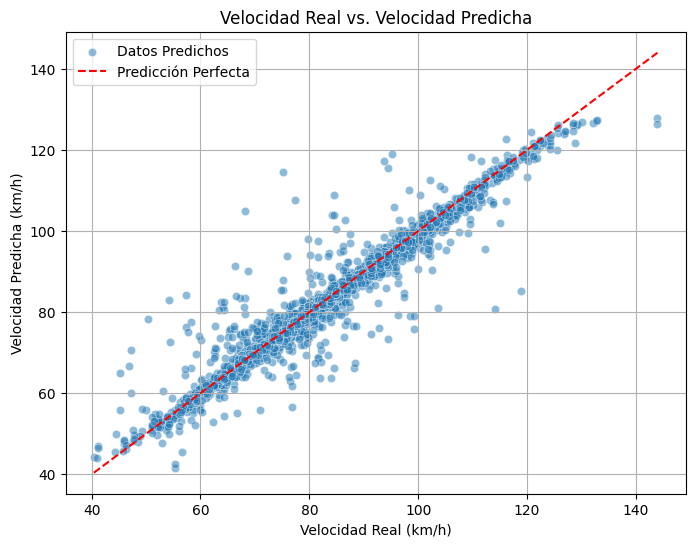

In [53]:
# 3. Gráfico de dispersión de Velocidad Real vs. Velocidad Predicha
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Velocidad Real', y='Velocidad Predicha', data=df_pred, alpha=0.5, label='Datos Predichos')
plt.plot([df_pred['Velocidad Real'].min(), df_pred['Velocidad Real'].max()],
         [df_pred['Velocidad Real'].min(), df_pred['Velocidad Real'].max()],
         color='red', linestyle='--', label='Predicción Perfecta')
plt.title('Velocidad Real vs. Velocidad Predicha')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Velocidad Predicha (km/h)')
plt.grid(True)
plt.legend()

plt.savefig('ims/scatter_real_vs_pred.svg', format='svg', bbox_inches='tight')
plt.show()


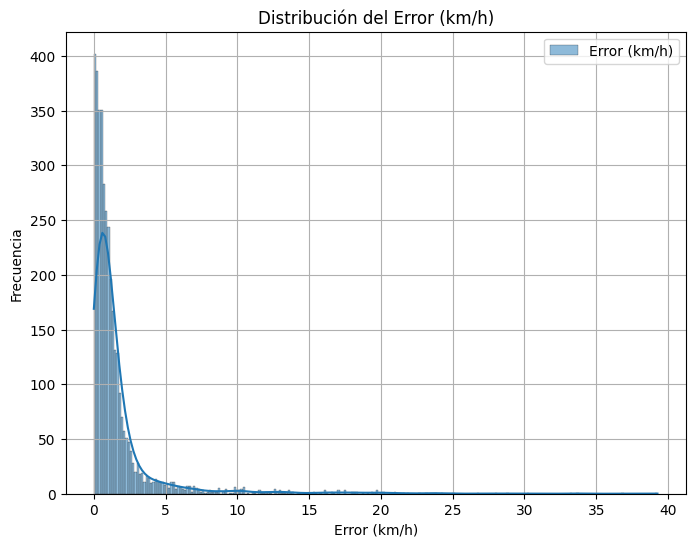

In [55]:
# 4. Histograma del Error
plt.figure(figsize=(8, 6))
sns.histplot(df_pred['Error km/h'], kde=True, label='Error (km/h)')  # Añade una etiqueta al histplot
plt.title('Distribución del Error (km/h)')
plt.xlabel('Error (km/h)')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.legend()
plt.savefig('ims/error_distribution.svg', format='svg', bbox_inches='tight')
plt.show()


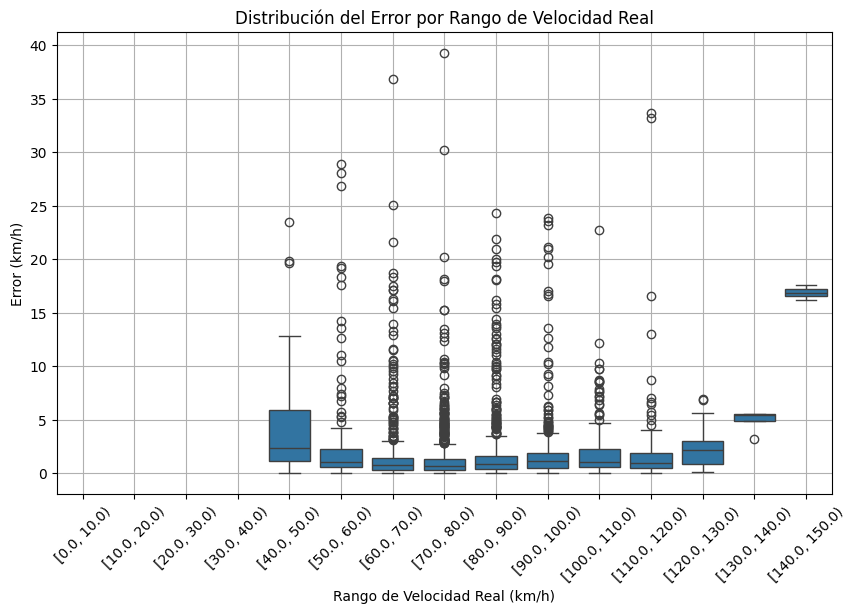

In [57]:
# 5. Gráfico de caja del Error por rangos de Velocidad Real
# Define los rangos de velocidad
bins = np.arange(0, df_pred['Velocidad Real'].max() + 10, 10)
df_pred['Rango Velocidad Real'] = pd.cut(df_pred['Velocidad Real'], bins=bins, right=False)

plt.figure(figsize=(10, 6))
sns.boxplot(x='Rango Velocidad Real', y='Error km/h', data=df_pred)
plt.title('Distribución del Error por Rango de Velocidad Real')
plt.xlabel('Rango de Velocidad Real (km/h)')
plt.ylabel('Error (km/h)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


/tmp/ipykernel_3897211/3169387029.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mae_por_rango = df_pred.groupby('Rango Velocidad Real')['Error km/h'].mean().reset_index()


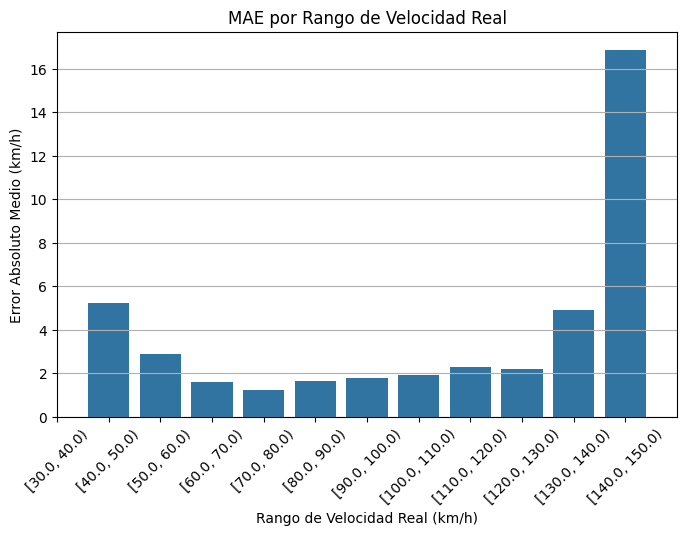

In [68]:
# 6. Gráfico de error absoluto medio (MAE) por rangos de Velocidad Real
mae_por_rango = df_pred.groupby('Rango Velocidad Real')['Error km/h'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(x='Rango Velocidad Real', y='Error km/h', data=mae_por_rango)
plt.title('MAE por Rango de Velocidad Real')
plt.xlabel('Rango de Velocidad Real (km/h)')
plt.ylabel('Error Absoluto Medio (km/h)')
plt.xticks(rotation=45)
plt.xlim(3, 15)
plt.grid(axis='y')
plt.savefig('ims/mae_speed_range.svg', format='svg', bbox_inches='tight')
plt.show()


In [28]:
metrics = pd.read_csv(f"{best_model_path}/metrics.csv")

aggreg_metrics = []
agg_col = "epoch"
for i, dfg in metrics.groupby(agg_col):
    agg = dict(dfg.mean())
    agg[agg_col] = i
    aggreg_metrics.append(agg)

df_metrics = pd.DataFrame(aggreg_metrics)

In [38]:
def plot_learning_curve(df_metrics, metric='loss', metric_name='Loss', title=None, save_path=None):
    plt.figure(figsize=(8, 5))
    plt.plot(df_metrics['epoch'], df_metrics[f'train_{metric}'], label=f'Train {metric_name}')
    plt.plot(df_metrics['epoch'], df_metrics[f'val_{metric}'], label=f'Validation {metric_name}')

    if title:
        plt.title(title)
    plt.xlabel('Época')
    plt.ylabel(f'{metric_name}')
    plt.yscale('log')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight')
        print(f"Gráfica guardada en: {save_path}")

    plt.show()

Gráfica guardada en: ims/learning_curve_loss.svg


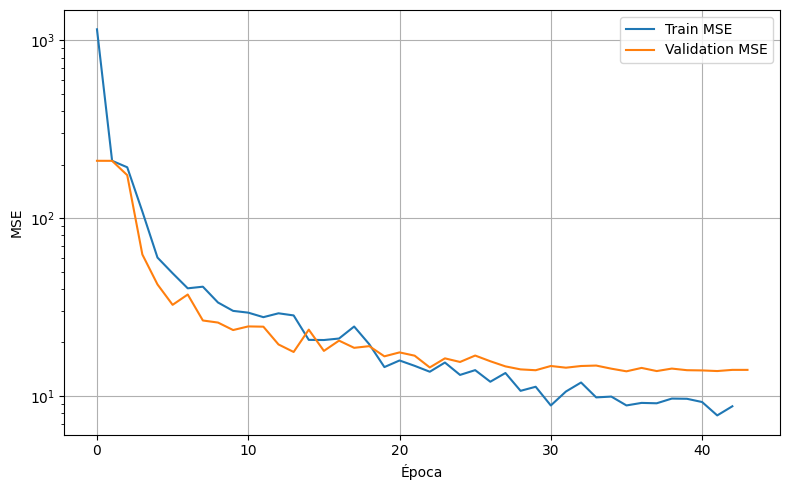

In [39]:
plot_learning_curve(df_metrics, metric='loss', metric_name='MSE', title='', save_path='ims/learning_curve_loss.svg')

Gráfica guardada en: ims/learning_curve_mse.svg


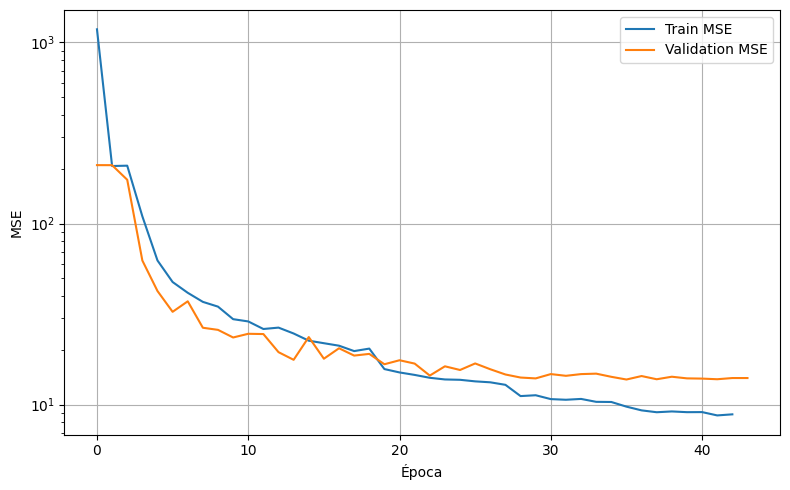

In [43]:
plot_learning_curve(df_metrics, metric='mse', metric_name='MSE', title='', save_path='ims/learning_curve_mse.svg')

Gráfica guardada en: ims/learning_curve_mae.svg


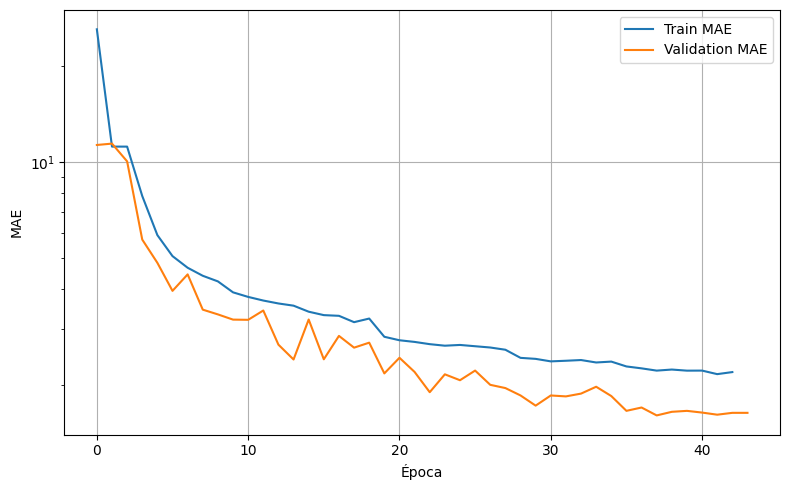

In [44]:
plot_learning_curve(df_metrics, metric='mae', metric_name='MAE', title='',save_path='ims/learning_curve_mae.svg')

Gráfica guardada en: ims/learning_curve_acc.svg


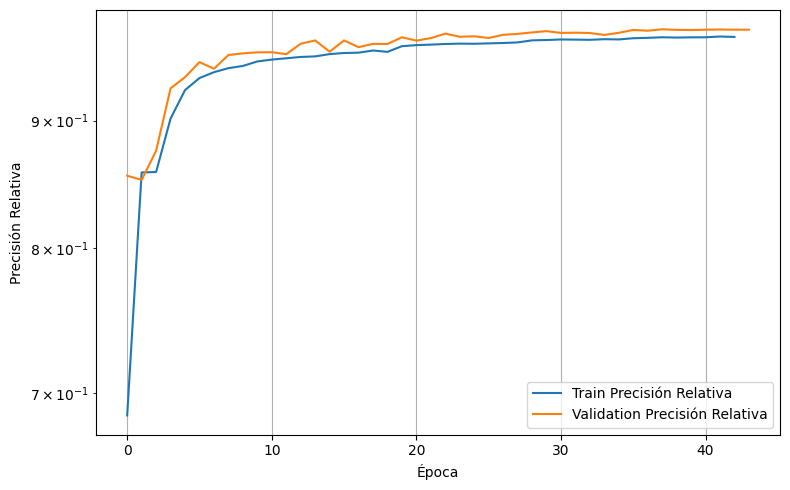

In [45]:
plot_learning_curve(df_metrics, metric='acc', metric_name='Precisión Relativa', title='', save_path='ims/learning_curve_acc.svg')